In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

# Define the data folder
data_path = Path("../data")

# Load datasets
employees = pd.read_csv(data_path / "employees.csv")
jobs = pd.read_csv(data_path / "jobs.csv")
compensation = pd.read_csv(data_path / "compensation.csv")
salary_bands = pd.read_csv(data_path / "salary_bands.csv")
performance = pd.read_csv(data_path / "performance.csv")
promotions = pd.read_csv(data_path / "promotions.csv")

# Verify dataset dimensions
datasets = {
    "Employees": employees,
    "Jobs": jobs,
    "Compensation": compensation,
    "Salary Bands": salary_bands,
    "Performance": performance,
    "Promotions": promotions
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Employees: (10000, 11)
Jobs: (50, 7)
Compensation: (30018, 7)
Salary Bands: (300, 7)
Performance: (30000, 4)
Promotions: (2737, 5)


In [3]:

# Work with a copy
employees = employees.copy()

# Fill missing education levels
employees["Education_Level"] = (
    employees["Education_Level"].fillna("Unknown")
)

# Convert hire date to datetime
employees["Hire_Date"] = pd.to_datetime(
    employees["Hire_Date"],
    errors="coerce"
)

# Flag experience data quality
employees["Experience_Quality_Flag"] = np.select(
    [
        employees["Years_Experience"].isna(),
        employees["Tenure_Years_2026"] > employees["Years_Experience"]
    ],
    ["Missing", "Review"],
    default="Valid"
)

# Validation
print("Employees Shape:", employees.shape)

print("\nMissing Values:")
print(employees.isna().sum())

print("\nExperience Quality:")
print(employees["Experience_Quality_Flag"].value_counts())

print("\nDuplicate Employee IDs:",
      employees["Employee_ID"].duplicated().sum())


Employees Shape: (10000, 12)

Missing Values:
Employee_ID                 0
Gender                      0
Age                         0
Education_Level             0
Location                    0
Hire_Date                   0
Years_Experience           25
Tenure_Years_2026           0
Job_ID                      0
Employment_Type             0
Employment_Status           0
Experience_Quality_Flag     0
dtype: int64

Experience Quality:
Experience_Quality_Flag
Valid      7643
Review     2332
Missing      25
Name: count, dtype: int64

Duplicate Employee IDs: 0


In [4]:

# Remove exact duplicate records
compensation = compensation.drop_duplicates().copy()

# Recover missing annual bonuses
missing_bonus = compensation["Annual_Bonus"].isna()

compensation.loc[missing_bonus, "Annual_Bonus"] = (
    compensation.loc[missing_bonus, "Total_Compensation"]
    - compensation.loc[missing_bonus, "Base_Salary"]
    - compensation.loc[missing_bonus, "Allowances"]
)

# Get employee hire years
hire_years = employees[["Employee_ID", "Hire_Date"]].copy()
hire_years["Hire_Year"] = hire_years["Hire_Date"].dt.year

# Merge hire year into compensation
compensation = compensation.merge(
    hire_years[["Employee_ID", "Hire_Year"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

# Remove compensation records before hire year
compensation = compensation[
    compensation["Compensation_Year"] >= compensation["Hire_Year"]
].copy()

# Remove temporary column
compensation.drop(columns="Hire_Year", inplace=True)

# Check compensation reconciliation
reconciliation_difference = (
    compensation["Total_Compensation"]
    - (
        compensation["Base_Salary"]
        + compensation["Annual_Bonus"]
        + compensation["Allowances"]
    )
).abs()

# Validation
print("Compensation Shape:", compensation.shape)
print("Missing Values:", compensation.isna().sum().sum())

print(
    "Duplicate Employee-Year Records:",
    compensation.duplicated(
        subset=["Employee_ID", "Compensation_Year"]
    ).sum()
)

print(
    "Maximum Reconciliation Difference:",
    round(reconciliation_difference.max(), 2)
)


Compensation Shape: (26305, 7)
Missing Values: 0
Duplicate Employee-Year Records: 0
Maximum Reconciliation Difference: 0.01


In [5]:

# Work with a copy
performance = performance.copy()

# Performance category to rating mapping
rating_map = {
    "Needs Improvement": 1,
    "Developing": 2,
    "Meets Expectations": 3,
    "Exceeds Expectations": 4,
    "Outstanding": 5
}

# Recover missing ratings using performance categories
missing_ratings = performance["Performance_Rating"].isna()

performance.loc[missing_ratings, "Performance_Rating"] = (
    performance.loc[missing_ratings, "Performance_Category"]
    .map(rating_map)
)

# Add employee hire year
performance = performance.merge(
    hire_years[["Employee_ID", "Hire_Year"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

# Remove performance records before hire year
performance = performance[
    performance["Review_Year"] >= performance["Hire_Year"]
].copy()

# Remove temporary column
performance.drop(columns="Hire_Year", inplace=True)

# Validate results
print("Performance Shape:", performance.shape)

print("Missing Values:",
      performance.isna().sum().sum())

print(
    "Duplicate Employee-Year Records:",
    performance.duplicated(
        subset=["Employee_ID", "Review_Year"]
    ).sum()
)

print(
    "Invalid Performance Ratings:",
    (~performance["Performance_Rating"].isin([1, 2, 3, 4, 5])).sum()
)


Performance Shape: (26305, 4)
Missing Values: 0
Duplicate Employee-Year Records: 0
Invalid Performance Ratings: 0


In [6]:

# Work with a copy
promotions = promotions.copy()

# Convert promotion date to datetime
promotions["Promotion_Date"] = pd.to_datetime(
    promotions["Promotion_Date"],
    errors="coerce"
)

# Add employee hire dates
promotions = promotions.merge(
    employees[["Employee_ID", "Hire_Date"]],
    on="Employee_ID",
    how="left",
    validate="many_to_one"
)

# Remove promotions before employee hire date
promotions = promotions[
    promotions["Promotion_Date"] >= promotions["Hire_Date"]
].copy()

# Remove temporary hire date column
promotions.drop(columns="Hire_Date", inplace=True)

# Validate results
print("Promotions Shape:", promotions.shape)

print("Missing Values:",
      promotions.isna().sum().sum())

print("Duplicate Promotion Records:",
      promotions.duplicated().sum())

print(
    "Average Salary Increase (%):",
    round(promotions["Salary_Increase_Pct"].mean(), 2)
)


Promotions Shape: (2605, 5)
Missing Values: 0
Duplicate Promotion Records: 0
Average Salary Increase (%): 14.57


In [7]:

# Validate Jobs dataset
print("JOBS DATASET")
print("Shape:", jobs.shape)
print("Missing Values:", jobs.isna().sum().sum())
print("Duplicate Job IDs:", jobs["Job_ID"].duplicated().sum())

print("\nSALARY BANDS DATASET")
print("Shape:", salary_bands.shape)
print("Missing Values:", salary_bands.isna().sum().sum())

# Check unique salary band combinations
print(
    "Duplicate Job-Location-Level Combinations:",
    salary_bands.duplicated(
        subset=["Job_ID", "Location", "Job_Level"]
    ).sum()
)

# Validate salary band boundaries
invalid_bands = (
    (salary_bands["Band_Min"] > salary_bands["Band_Mid"])
    | (salary_bands["Band_Mid"] > salary_bands["Band_Max"])
)

print("Invalid Salary Band Ranges:", invalid_bands.sum())


JOBS DATASET
Shape: (50, 7)
Missing Values: 0
Duplicate Job IDs: 0

SALARY BANDS DATASET
Shape: (300, 7)
Missing Values: 0
Duplicate Job-Location-Level Combinations: 0
Invalid Salary Band Ranges: 0


In [8]:

# Select 2026 compensation records
compensation_2026 = compensation[
    compensation["Compensation_Year"] == 2026
].copy()

# Merge employee and job information
pay_equity_2026 = employees.merge(
    jobs,
    on="Job_ID",
    how="left",
    validate="many_to_one"
)

# Add 2026 compensation
pay_equity_2026 = pay_equity_2026.merge(
    compensation_2026,
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Add salary band information
pay_equity_2026 = pay_equity_2026.merge(
    salary_bands[
        ["Job_ID", "Location", "Job_Level",
         "Band_Min", "Band_Mid", "Band_Max"]
    ],
    on=["Job_ID", "Location", "Job_Level"],
    how="left",
    validate="many_to_one"
)

# Validate merged dataset
print("Pay Equity Dataset Shape:", pay_equity_2026.shape)

print(
    "Unique Employees:",
    pay_equity_2026["Employee_ID"].nunique()
)

print(
    "Duplicate Employee IDs:",
    pay_equity_2026["Employee_ID"].duplicated().sum()
)

print(
    "Missing Base Salaries:",
    pay_equity_2026["Base_Salary"].isna().sum()
)

print(
    "Missing Salary Bands:",
    pay_equity_2026["Band_Min"].isna().sum()
)

print("\nDataset Preview:")
display(pay_equity_2026.head())


Pay Equity Dataset Shape: (10000, 27)
Unique Employees: 10000
Duplicate Employee IDs: 0
Missing Base Salaries: 0
Missing Salary Bands: 0

Dataset Preview:


,Employee_ID,Gender,Age,Education_Level,Location,Hire_Date,Years_Experience,Tenure_Years_2026,Job_ID,Employment_Type,Employment_Status,Experience_Quality_Flag,Job_Title,Department,Job_Family,Job_Level,Min_Experience,Max_Experience,Compensation_Year,Base_Salary,Annual_Bonus,Allowances,Total_Compensation,Currency,Band_Min,Band_Mid,Band_Max
0,E00001,Male,21,Master's,Chennai,2025-02-16,0.00,1.90,J038,Full-time,Active,Review,Customer Support Associate,Customer Success,Customer Support,1,0,3,2026,"356,316.72","30,385.94","14,257.08","400,959.74",INR,295620,379000,473750
1,E00002,Female,28,Doctorate,Chennai,2020-07-28,7.00,6.40,J003,Full-time,Active,Valid,Senior HR Analyst,Human Resources,People Analytics,3,4,8,2026,"965,820.31","91,481.07","26,430.95","1,083,732.32",INR,823680,1056000,1320000
2,E00003,Male,27,Bachelor's,Bengaluru,2024-05-20,2.00,2.60,J038,Full-time,Active,Review,Customer Support Associate,Customer Success,Customer Support,1,0,3,2026,"379,142.07","20,792.46","9,443.88","409,378.41",INR,325260,417000,521250
3,E00004,Male,29,Bachelor's,Bengaluru,2026-09-19,4.00,0.30,J040,Full-time,Active,Valid,Senior Customer Success Specialist,Customer Success,Customer Success,3,5,9,2026,"1,034,198.43","82,741.70","17,805.09","1,134,745.22",INR,852540,1093000,1366250
4,E00005,Female,36,Master's,Hyderabad,2026-06-07,11.00,0.60,J008,Full-time,Active,Valid,Finance Manager,Finance,Financial Planning,4,7,12,2026,"1,735,232.87","266,221.62","68,268.22","2,069,722.71",INR,1418820,1819000,2273750


In [9]:

# Step 10 — Final Pay Equity Dataset Validation

# Check employee and compensation records
print("Total Employees:", len(pay_equity_2026))

print(
    "Unique Employees:",
    pay_equity_2026["Employee_ID"].nunique()
)

print(
    "Compensation Year:",
    pay_equity_2026["Compensation_Year"].unique()
)

# Check salary values
print(
    "Missing Base Salaries:",
    pay_equity_2026["Base_Salary"].isna().sum()
)

print(
    "Invalid Base Salaries:",
    (pay_equity_2026["Base_Salary"] <= 0).sum()
)

# Check salary band boundaries
invalid_band_ranges = (
    (pay_equity_2026["Band_Min"] > pay_equity_2026["Band_Mid"]) |
    (pay_equity_2026["Band_Mid"] > pay_equity_2026["Band_Max"])
)

print(
    "Invalid Salary Band Ranges:",
    invalid_band_ranges.sum()
)

# Check gender and job information
print(
    "Missing Gender Values:",
    pay_equity_2026["Gender"].isna().sum()
)

print(
    "Missing Job Levels:",
    pay_equity_2026["Job_Level"].isna().sum()
)

print(
    "Missing Departments:",
    pay_equity_2026["Department"].isna().sum()
)

print(
    "Missing Locations:",
    pay_equity_2026["Location"].isna().sum()
)

# Display any invalid salary band records
if invalid_band_ranges.any():
    display(
        pay_equity_2026.loc[
            invalid_band_ranges,
            ["Employee_ID", "Job_ID", "Location",
             "Band_Min", "Band_Mid", "Band_Max"]
        ]
    )


Total Employees: 10000
Unique Employees: 10000
Compensation Year: [2026]
Missing Base Salaries: 0
Invalid Base Salaries: 0
Invalid Salary Band Ranges: 0
Missing Gender Values: 0
Missing Job Levels: 0
Missing Departments: 0
Missing Locations: 0


### Overall Gender Pay Gap — Methodology

The unadjusted gender pay gap measures the percentage difference between average male and female base salaries.

**Formula:**

$$
\text{Gender Pay Gap (\%)} =
\frac{\text{Avg Male Salary} - \text{Avg Female Salary}}
{\text{Avg Male Salary}} \times 100
$$

- **Positive gap:** Average male salary is higher.
- **Negative gap:** Average female salary is higher.
- **Zero gap:** Both groups have equal average salaries.

**Note:** This is an unadjusted comparison and does not account for job level, department, location, experience, or performance.

,Gender,Employees,Avg_Base_Salary,Median_Base_Salary
0,Female,4738,"2,035,345.26","1,558,756.33"
1,Male,5150,"2,060,003.00","1,568,888.16"
2,Non-binary,112,"1,991,310.25","1,414,448.90"


Overall Male-Female Pay Gap (%): 1.2
Total Employees: 10000


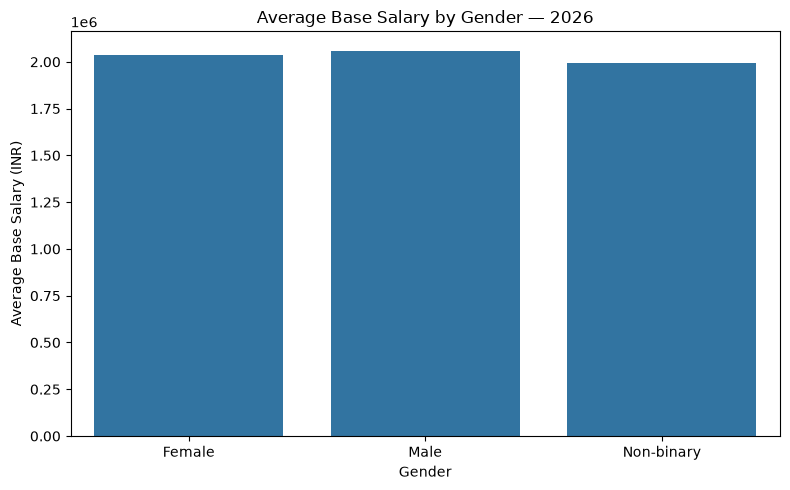

In [10]:

# Step 11 — Overall Gender Pay Gap Analysis (2026)

# Summarize base salaries by gender
gender_pay_summary = (
    pay_equity_2026.groupby("Gender")
    .agg(
        Employees=("Employee_ID", "count"),
        Avg_Base_Salary=("Base_Salary", "mean"),
        Median_Base_Salary=("Base_Salary", "median")
    )
    .reset_index()
)

gender_pay_summary[
    ["Avg_Base_Salary", "Median_Base_Salary"]
] = gender_pay_summary[
    ["Avg_Base_Salary", "Median_Base_Salary"]
].round(2)

display(gender_pay_summary)

# Calculate male-female average pay gap
male_avg = gender_pay_summary.loc[
    gender_pay_summary["Gender"] == "Male",
    "Avg_Base_Salary"
].iloc[0]

female_avg = gender_pay_summary.loc[
    gender_pay_summary["Gender"] == "Female",
    "Avg_Base_Salary"
].iloc[0]

gender_pay_gap = (
    (male_avg - female_avg) / male_avg * 100
)

print(
    "Overall Male-Female Pay Gap (%):",
    round(gender_pay_gap, 2)
)

print(
    "Total Employees:",
    gender_pay_summary["Employees"].sum()
)

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_pay_summary,
    x="Gender",
    y="Avg_Base_Salary"
)

plt.title("Average Base Salary by Gender — 2026")
plt.xlabel("Gender")
plt.ylabel("Average Base Salary (INR)")
plt.tight_layout()
plt.show()


### Key Findings — Overall Gender Pay Gap (2026)

- The analysis covers **10,000 employees**, including 4,738 female, 5,150 male, and 112 non-binary employees.
- Male employees earn an average base salary of **₹20,60,003.00**, compared with **₹20,35,345.26** for female employees.
- The overall unadjusted male–female pay gap is **1.20%**, indicating a small difference in average base salaries.
- Median salaries also show a slightly higher value for male employees.
- These results do not establish whether employees receive unequal pay for comparable work. Further analysis by job level, department, location, and experience is required.

### Gender Pay Gap by Job Level — Methodology

This analysis compares average male and female base salaries within each job level.

**Formula:**

$$
\text{Pay Gap (\%)} =
\frac{\text{Avg Male Salary} - \text{Avg Female Salary}}
{\text{Avg Male Salary}} \times 100
$$

- **Positive gap:** Average male salary is higher.
- **Negative gap:** Average female salary is higher.
- **Zero gap:** Both groups have equal average salaries.

**Note:** Comparing employees within the same job level reduces differences caused by seniority, but does not control for department, location, experience, or performance.

Gender,Job_Level,Male_Count,Female_Count,Male,Female,Pay_Gap_Pct
0,1,322,277,"404,245.90","392,017.69",3.02
1,2,1144,1026,"725,378.37","715,137.35",1.41
2,3,1046,992,"1,209,007.63","1,175,199.19",2.80
3,4,1402,1294,"1,900,184.16","1,864,280.02",1.89
4,5,518,477,"3,337,541.57","3,276,591.28",1.83
5,6,718,672,"5,559,176.49","5,446,482.22",2.03


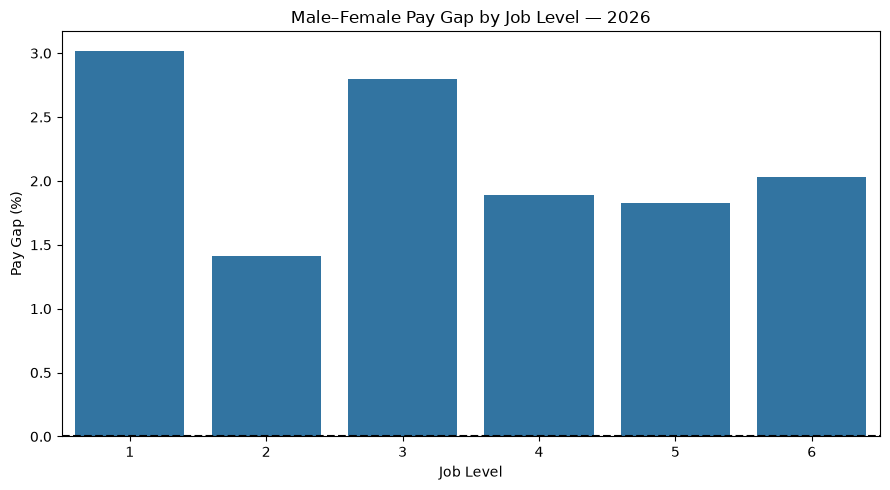

In [11]:

# Step 12 — Gender Pay Gap by Job Level

# Select male and female employees for this comparison
gender_level_data = pay_equity_2026[
    pay_equity_2026["Gender"].isin(["Male", "Female"])
].copy()

# Calculate average base salary by job level and gender
level_salary = (
    gender_level_data.groupby(["Job_Level", "Gender"])
    ["Base_Salary"]
    .mean()
    .unstack()
)

# Calculate employee counts
level_counts = (
    gender_level_data.groupby(["Job_Level", "Gender"])
    ["Employee_ID"]
    .count()
    .unstack(fill_value=0)
)

# Calculate gender pay gap
level_salary["Pay_Gap_Pct"] = (
    (level_salary["Male"] - level_salary["Female"])
    / level_salary["Male"] * 100
)

# Prepare final summary
job_level_pay_gap = level_salary.reset_index()

job_level_pay_gap["Male_Count"] = (
    job_level_pay_gap["Job_Level"].map(level_counts["Male"])
)

job_level_pay_gap["Female_Count"] = (
    job_level_pay_gap["Job_Level"].map(level_counts["Female"])
)

job_level_pay_gap = job_level_pay_gap[
    ["Job_Level", "Male_Count", "Female_Count",
     "Male", "Female", "Pay_Gap_Pct"]
].round(2)

display(job_level_pay_gap)

# Visualize gender pay gap by job level
plt.figure(figsize=(9, 5))

sns.barplot(
    data=job_level_pay_gap,
    x="Job_Level",
    y="Pay_Gap_Pct"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Male–Female Pay Gap by Job Level — 2026")
plt.xlabel("Job Level")
plt.ylabel("Pay Gap (%)")
plt.tight_layout()
plt.show()


### Gender Pay Equity Within Comparable Job Groups

**Objective:** Identify salary differences between male and female employees working in comparable job groups.

Employees are grouped using:

- Job ID
- Location

Since each Job ID identifies a specific job, this comparison also aligns employees by job level.

**Pay Gap Formula:**

$$
\text{Pay Gap (\%)} =
\frac{\text{Male Avg Salary} - \text{Female Avg Salary}}
{\text{Male Avg Salary}} \times 100
$$

Only groups containing at least **5 male and 5 female employees** are included to reduce the influence of very small groups.

- **Positive gap:** Higher average male salaries.
- **Negative gap:** Higher average female salaries.
- **Zero gap:** Equal average male and female salaries.

**Note:** This analysis controls for job and location through grouping, but does not yet adjust for individual experience, performance, or tenure.

In [12]:

# Step 13 — Gender Pay Equity Within Comparable Job Groups

# Select male and female employees
comparable_data = pay_equity_2026[
    pay_equity_2026["Gender"].isin(["Male", "Female"])
].copy()

# Calculate salary and employee count by job and location
group_summary = (
    comparable_data.groupby(
        ["Job_ID", "Job_Title", "Job_Level", "Location", "Gender"]
    )
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Salary=("Base_Salary", "mean")
    )
    .reset_index()
)

# Create separate columns for male and female employees
comparable_groups = group_summary.pivot(
    index=["Job_ID", "Job_Title", "Job_Level", "Location"],
    columns="Gender",
    values=["Employee_Count", "Avg_Salary"]
)

# Flatten column names
comparable_groups.columns = [
    f"{metric}_{gender}"
    for metric, gender in comparable_groups.columns
]

comparable_groups = comparable_groups.reset_index()

# Include groups with at least 5 employees of each gender
comparable_groups = comparable_groups[
    (comparable_groups["Employee_Count_Male"] >= 5) &
    (comparable_groups["Employee_Count_Female"] >= 5)
].copy()

# Calculate within-group pay gap
comparable_groups["Pay_Gap_Pct"] = (
    (
        comparable_groups["Avg_Salary_Male"]
        - comparable_groups["Avg_Salary_Female"]
    )
    / comparable_groups["Avg_Salary_Male"] * 100
)

# Round salary and percentage columns
salary_columns = [
    "Avg_Salary_Male",
    "Avg_Salary_Female",
    "Pay_Gap_Pct"
]

comparable_groups[salary_columns] = (
    comparable_groups[salary_columns].round(2)
)

# Summary results
print("Comparable Job Groups:", len(comparable_groups))

print(
    "Groups with Higher Male Average Salary:",
    (comparable_groups["Pay_Gap_Pct"] > 0).sum()
)

print(
    "Groups with Higher Female Average Salary:",
    (comparable_groups["Pay_Gap_Pct"] < 0).sum()
)

print(
    "Average Within-Group Pay Gap (%):",
    round(comparable_groups["Pay_Gap_Pct"].mean(), 2)
)

print("\nTop 10 Groups with Largest Male-Favoring Pay Gaps:")

display(
    comparable_groups.sort_values(
        "Pay_Gap_Pct", ascending=False
    ).head(10)
)


Comparable Job Groups: 281
Groups with Higher Male Average Salary: 227
Groups with Higher Female Average Salary: 54
Average Within-Group Pay Gap (%): 1.86

Top 10 Groups with Largest Male-Favoring Pay Gaps:


,Job_ID,Job_Title,Job_Level,Location,Employee_Count_Female,Employee_Count_Male,Avg_Salary_Female,Avg_Salary_Male,Pay_Gap_Pct
33,J006,Financial Analyst,2,Hyderabad,9.00,5.00,"669,244.65","742,477.54",9.86
235,J040,Senior Customer Success Specialist,3,Chennai,11.00,10.00,"913,176.64","1,011,641.13",9.73
122,J021,Senior QA Engineer,3,Gurugram,5.00,5.00,"1,306,787.72","1,443,102.81",9.45
50,J009,Accountant,2,Gurugram,8.00,9.00,"719,530.86","781,603.51",7.94
166,J028,Senior Marketing Analyst,3,Mumbai,12.00,9.00,"1,177,477.31","1,279,009.86",7.94
224,J038,Customer Support Associate,1,Gurugram,7.00,5.00,"361,454.50","392,580.87",7.93
38,J007,Senior Financial Analyst,3,Gurugram,9.00,8.00,"1,159,493.59","1,255,875.15",7.67
11,J002,HR Analyst,2,Pune,6.00,9.00,"632,000.79","683,702.41",7.56
153,J026,Marketing Executive,1,Hyderabad,8.00,14.00,"375,170.72","404,082.16",7.15
139,J024,Senior Account Executive,3,Chennai,17.00,10.00,"1,068,889.38","1,151,123.64",7.14


### Key Findings — Comparable Job Group Pay Equity

- **281 comparable job groups** met the minimum requirement of five male and five female employees.
- Male employees had higher average base salaries in **227 groups (80.78%)**, while female employees had higher averages in **54 groups (19.22%)**.
- The average unweighted within-group male–female pay gap was **1.86%**.
- The largest observed male-favoring gap was **9.86%**, among Financial Analysts in Hyderabad.
- These findings suggest a consistent pattern of higher average male salaries across many comparable groups, warranting further investigation.
- The analysis does not yet account for differences in employee experience, tenure, or performance and cannot independently establish pay discrimination.

In [13]:

# Step 14 — Comparable Job Group Employee Coverage

# Total male and female employees
total_binary_employees = len(comparable_data)

# Employees included in eligible comparable groups
covered_male = int(
    comparable_groups["Employee_Count_Male"].sum()
)

covered_female = int(
    comparable_groups["Employee_Count_Female"].sum()
)

covered_employees = covered_male + covered_female

# Employees excluded by the minimum group-size rule
excluded_employees = (
    total_binary_employees - covered_employees
)

# Calculate coverage percentage
coverage_pct = (
    covered_employees / total_binary_employees * 100
)

print("Total Male and Female Employees:",
      total_binary_employees)

print("Employees in Comparable Groups:",
      covered_employees)

print("Male Employees Covered:", covered_male)

print("Female Employees Covered:", covered_female)

print("Employees Excluded:", excluded_employees)

print("Employee Coverage (%):",
      round(coverage_pct, 2))

print("Comparable Groups:",
      len(comparable_groups))


Total Male and Female Employees: 9888
Employees in Comparable Groups: 9628
Male Employees Covered: 4989
Female Employees Covered: 4639
Employees Excluded: 260
Employee Coverage (%): 97.37
Comparable Groups: 281


### Key Findings — Comparable Group Coverage

- **9,628 of 9,888 male and female employees (97.37%)** are represented in the comparable job groups.
- The analysis includes 4,989 male and 4,639 female employees across 281 eligible groups.
- Only 260 employees (2.63%) were excluded because their groups did not meet the minimum gender-specific sample size.
- The high coverage indicates that the comparable-group analysis represents most male and female employees in the dataset.
- The remaining analysis will examine whether observed salary differences persist after accounting for employee characteristics.

### Employee-Weighted Comparable Group Pay Gap

**Objective:** Calculate a group-size-weighted average of the male–female pay gaps across comparable job groups.

**Formula:**

$$
\text{Weighted Pay Gap (\%)} =
\frac{\sum(\text{Group Pay Gap} \times \text{Group Employees})}
{\sum \text{Group Employees}}
$$

Each group's weight equals its total number of male and female employees.

- **Larger groups:** Have more influence on the overall weighted result.
- **Smaller groups:** Have less influence on the overall weighted result.

**Note:** This measure is a descriptive weighted average, not a fully adjusted individual-level pay gap.

In [14]:

# Step 15 — Employee-Weighted Comparable Group Pay Gap

# Work with a copy of comparable groups
weighted_groups = comparable_groups.copy()

# Calculate total employees per group
weighted_groups["Total_Employees"] = (
    weighted_groups["Employee_Count_Male"]
    + weighted_groups["Employee_Count_Female"]
)

# Calculate group-size-weighted pay gap
weighted_pay_gap = (
    (
        weighted_groups["Pay_Gap_Pct"]
        * weighted_groups["Total_Employees"]
    ).sum()
    / weighted_groups["Total_Employees"].sum()
)

# Compare weighted and unweighted results
unweighted_pay_gap = (
    weighted_groups["Pay_Gap_Pct"].mean()
)

print(
    "Comparable Job Groups:",
    len(weighted_groups)
)

print(
    "Employees Covered:",
    int(weighted_groups["Total_Employees"].sum())
)

print(
    "Unweighted Average Pay Gap (%):",
    round(unweighted_pay_gap, 2)
)

print(
    "Employee-Weighted Pay Gap (%):",
    round(weighted_pay_gap, 2)
)

print(
    "Difference (Percentage Points):",
    round(weighted_pay_gap - unweighted_pay_gap, 2)
)


Comparable Job Groups: 281
Employees Covered: 9628
Unweighted Average Pay Gap (%): 1.86
Employee-Weighted Pay Gap (%): 1.89
Difference (Percentage Points): 0.03


### Key Findings — Employee-Weighted Gender Pay Gap

- The analysis covers **9,628 employees across 281 comparable job groups**.
- The unweighted average male–female pay gap is **1.86%**.
- After weighting each group by employee count, the average pay gap increases slightly to **1.89%**.
- The difference of **0.03 percentage points** indicates that group size has a limited effect on the observed pay gap.
- Both measures indicate higher average male base salaries within comparable job groups.
- Further analysis is required to determine whether differences in experience, tenure, and performance help explain the observed gaps.

### Experience-Adjusted Comparable Group Analysis

**Objective:** Examine gender pay differences among employees with similar job roles, locations, and years of experience.

Employees are grouped by:

- Job ID
- Location
- Experience group: 0–3, 4–7, 8–12, and 13+ years

**Formula:**

$$
\text{Pay Gap (\%)} =
\frac{\text{Male Avg Salary} - \text{Female Avg Salary}}
{\text{Male Avg Salary}} \times 100
$$

Only groups containing at least **3 male and 3 female employees** are included.

- **Positive gap:** Higher average male salaries.
- **Negative gap:** Higher average female salaries.
- **Zero gap:** Equal average male and female salaries.

**Note:** This is an experience-stratified comparison, not a fully adjusted statistical model. Employees with missing experience values are excluded from this specific analysis.

In [15]:

# Step 16 — Experience-Adjusted Comparable Group Analysis

experience_data = pay_equity_2026[
    pay_equity_2026["Gender"].isin(["Male", "Female"])
    & pay_equity_2026["Years_Experience"].notna()
].copy()

# Create experience groups
experience_data["Experience_Group"] = pd.cut(
    experience_data["Years_Experience"],
    bins=[-1, 3, 7, 12, float("inf")],
    labels=["0-3 Years", "4-7 Years",
            "8-12 Years", "13+ Years"]
)

# Calculate salary and employee count
experience_summary = (
    experience_data.groupby(
        ["Job_ID", "Location", "Experience_Group", "Gender"],
        observed=True
    )
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Salary=("Base_Salary", "mean")
    )
    .reset_index()
)

# Separate male and female values
experience_groups = experience_summary.pivot(
    index=["Job_ID", "Location", "Experience_Group"],
    columns="Gender",
    values=["Employee_Count", "Avg_Salary"]
)

experience_groups.columns = [
    f"{metric}_{gender}"
    for metric, gender in experience_groups.columns
]

experience_groups = experience_groups.reset_index()

# Require at least 3 employees per gender
experience_groups = experience_groups[
    (experience_groups["Employee_Count_Male"] >= 3)
    & (experience_groups["Employee_Count_Female"] >= 3)
].copy()

# Calculate pay gap
experience_groups["Pay_Gap_Pct"] = (
    (experience_groups["Avg_Salary_Male"]
     - experience_groups["Avg_Salary_Female"])
    / experience_groups["Avg_Salary_Male"] * 100
)

# Calculate group employee totals
experience_groups["Total_Employees"] = (
    experience_groups["Employee_Count_Male"]
    + experience_groups["Employee_Count_Female"]
)

# Weighted pay gap
experience_weighted_gap = (
    (
        experience_groups["Pay_Gap_Pct"]
        * experience_groups["Total_Employees"]
    ).sum()
    / experience_groups["Total_Employees"].sum()
)

print("Comparable Experience Groups:", len(experience_groups))

print(
    "Employees Covered:",
    int(experience_groups["Total_Employees"].sum())
)

print(
    "Experience-Stratified Weighted Pay Gap (%):",
    round(experience_weighted_gap, 2)
)

print("\nPay Gap by Experience Group:")

experience_group_results = (
    experience_groups.groupby(
        "Experience_Group", observed=True
    )
    .apply(
        lambda x: pd.Series({
            "Comparable_Groups": len(x),
            "Employees": int(x["Total_Employees"].sum()),
            "Weighted_Pay_Gap_Pct": (
                (x["Pay_Gap_Pct"] * x["Total_Employees"]).sum()
                / x["Total_Employees"].sum()
            )
        }),
        include_groups=False
    )
    .round(2)
)

display(experience_group_results)


Comparable Experience Groups: 415
Employees Covered: 8416
Experience-Stratified Weighted Pay Gap (%): 1.95

Pay Gap by Experience Group:


,Comparable_Groups,Employees,Weighted_Pay_Gap_Pct
Experience_Group,,,
0-3 Years,95.00,"1,179.00",1.84
4-7 Years,85.00,917.00,1.85
8-12 Years,149.00,"2,297.00",2.23
13+ Years,86.00,"4,023.00",1.85


### Key Findings — Experience-Stratified Pay Equity

- The analysis includes **8,416 employees across 415 comparable groups**, based on job, location, and experience.
- The experience-stratified weighted male–female pay gap is **1.95%**.
- All four experience categories show positive male–female average salary gaps.
- Employees with **8–12 years of experience** have the highest observed gap at **2.23%**.
- The results indicate that differences remain after grouping employees by experience, but further analysis is needed to assess the influence of tenure and performance.
- These descriptive differences do not independently establish unequal pay for equivalent work.


## Salary Band Positioning — Pay Equity Analysis

## Objective

Compare male and female employees' relative salary positions within their assigned salary bands.

## Salary Band Position Formula

$$
\text{Band Position (\%)} =
\frac{\text{Base Salary} - \text{Band Minimum}}
{\text{Band Maximum} - \text{Band Minimum}}
\times 100
$$

### Interpretation

- **0%:** Salary equals the band minimum.
- **50%:** Salary is halfway between the band minimum and maximum.
- **100%:** Salary equals the band maximum.
- **Below 0%:** Salary is below the band minimum.
- **Above 100%:** Salary exceeds the band maximum.

## Analysis Methodology

1. Calculate each employee's salary band position using the formula above.
2. Group employees by **job and location** to ensure like-for-like comparisons.
3. Calculate the average band position separately for male and female employees within each group.
4. Include only groups with at least **five male and five female employees** to support meaningful comparisons.
5. Compare the average band positions to identify potential gender-based differences in salary positioning.

## Key Metric

**Gender Difference in Average Band Position (percentage points)**

$$
\begin{aligned}
\text{Gender Difference} ={}&
\text{Average Female Band Position}\\
&- \text{Average Male Band Position}
\end{aligned}
$$

### Interpretation of Results

- **Negative difference:** Female employees are positioned lower in their salary bands on average.
- **Positive difference:** Female employees are positioned higher in their salary bands on average.
- **Zero difference:** Both groups have the same average salary band position.

## Important Considerations

Differences in salary band positioning may indicate potential pay equity concerns. However, these differences should be investigated alongside relevant factors such as tenure, experience, performance, and job level before drawing conclusions about gender-based pay inequity.


In [16]:

# Step 17 — Salary Band Positioning by Gender

band_equity_data = comparable_data.copy()

# Calculate position within salary band
band_equity_data["Band_Position_Pct"] = (
    (
        band_equity_data["Base_Salary"]
        - band_equity_data["Band_Min"]
    )
    / (
        band_equity_data["Band_Max"]
        - band_equity_data["Band_Min"]
    ) * 100
)

# Summarize by job, location and gender
band_group_summary = (
    band_equity_data.groupby(
        ["Job_ID", "Location", "Gender"]
    )
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Band_Position=("Band_Position_Pct", "mean")
    )
    .reset_index()
)

# Separate male and female results
band_position_groups = band_group_summary.pivot(
    index=["Job_ID", "Location"],
    columns="Gender",
    values=["Employee_Count", "Avg_Band_Position"]
)

band_position_groups.columns = [
    f"{metric}_{gender}"
    for metric, gender in band_position_groups.columns
]

band_position_groups = band_position_groups.reset_index()

# Apply minimum group size
band_position_groups = band_position_groups[
    (band_position_groups["Employee_Count_Male"] >= 5)
    & (band_position_groups["Employee_Count_Female"] >= 5)
].copy()

# Difference in percentage points
band_position_groups["Position_Gap_PP"] = (
    band_position_groups["Avg_Band_Position_Male"]
    - band_position_groups["Avg_Band_Position_Female"]
)

# Calculate employee-weighted average difference
band_position_groups["Total_Employees"] = (
    band_position_groups["Employee_Count_Male"]
    + band_position_groups["Employee_Count_Female"]
)

weighted_position_gap = (
    (
        band_position_groups["Position_Gap_PP"]
        * band_position_groups["Total_Employees"]
    ).sum()
    / band_position_groups["Total_Employees"].sum()
)

print("Comparable Job Groups:", len(band_position_groups))

print(
    "Employees Covered:",
    int(band_position_groups["Total_Employees"].sum())
)

print(
    "Weighted Band Position Gap (Percentage Points):",
    round(weighted_position_gap, 2)
)

print(
    "Groups with Higher Male Band Position:",
    (band_position_groups["Position_Gap_PP"] > 0).sum()
)

print(
    "Groups with Higher Female Band Position:",
    (band_position_groups["Position_Gap_PP"] < 0).sum()
)

print("\nTop 10 Largest Male-Favoring Band Position Gaps:")

display(
    band_position_groups.sort_values(
        "Position_Gap_PP", ascending=False
    ).head(10).round(2)
)


Comparable Job Groups: 281
Employees Covered: 9628
Weighted Band Position Gap (Percentage Points): 4.09
Groups with Higher Male Band Position: 227
Groups with Higher Female Band Position: 54

Top 10 Largest Male-Favoring Band Position Gaps:


,Job_ID,Location,Employee_Count_Female,Employee_Count_Male,Avg_Band_Position_Female,Avg_Band_Position_Male,Position_Gap_PP,Total_Employees
235,J040,Chennai,11.00,10.00,29.90,51.02,21.12,21.00
122,J021,Gurugram,5.00,5.00,34.22,55.10,20.88,10.00
33,J006,Hyderabad,9.00,5.00,24.15,44.96,20.80,14.00
166,J028,Mumbai,12.00,9.00,33.35,50.53,17.19,21.00
50,J009,Gurugram,8.00,9.00,25.17,41.66,16.49,17.00
38,J007,Gurugram,9.00,8.00,29.99,46.28,16.29,17.00
224,J038,Gurugram,7.00,5.00,20.25,36.29,16.04,12.00
11,J002,Pune,6.00,9.00,26.14,41.85,15.71,15.00
139,J024,Chennai,17.00,10.00,34.95,50.40,15.46,27.00
280,J047,Mumbai,9.00,7.00,32.03,47.01,14.99,16.00


### Key Findings — Salary Band Positioning by Gender

- The analysis covers **9,628 employees across 281 comparable job groups**.
- The employee-weighted average salary band positioning gap is **4.09 percentage points**, favoring male employees.
- Male employees have higher average band positions in **227 groups**, compared with 54 groups favoring female employees.
- The largest observed positioning difference is **21.12 percentage points** for Senior Customer Success Specialists in Chennai.
- These findings indicate that salary differences exist even among employees assigned to the same job and location.
- Further investigation of tenure, experience, and performance is needed before drawing conclusions about unexplained pay differences.


# Performance-Stratified Gender Pay Equity

## Objective

Compare male and female base salaries among employees with the same job, location, and performance rating.

## Comparison Variables

- **Job ID**
- **Location**
- **2026 Performance Rating**
- **Gender**

## Pay Gap Formula

$$
\text{Pay Gap (\%)} =
\frac{\text{Male Avg Salary} - \text{Female Avg Salary}}
{\text{Male Avg Salary}} \times 100
$$

## Analysis Methodology

1. Group employees by **Job ID, Location, and 2026 Performance Rating**.
2. Calculate the average base salary separately for male and female employees within each group.
3. Include only groups containing at least **three male and three female employees**.
4. Calculate the pay gap percentage for each eligible group using the formula above.
5. Compare the results across groups to identify potential gender-based differences in base salaries among employees with comparable job, location, and performance ratings.

## Interpretation of Results

- **Positive pay gap:** Male employees earn more than female employees on average.
- **Negative pay gap:** Female employees earn more than male employees on average.
- **Zero pay gap:** Male and female employees have the same average base salary.

## Important Considerations

This is a **performance-stratified comparison**, rather than a fully adjusted statistical model. It controls for differences in job, location, and performance rating by comparing employees within the same groups. However, it does not account for other potentially relevant factors, such as tenure, experience, working hours, or job level differences within the same job ID.

The findings should be interpreted as indicators of potential pay equity differences, rather than definitive evidence of gender-based pay discrimination.


In [17]:

# Step 18 — Performance-Stratified Gender Pay Equity

# Select 2026 performance records
performance_2026 = performance[
    performance["Review_Year"] == 2026
][["Employee_ID", "Performance_Rating"]].copy()

# Add performance ratings to comparable employees
performance_equity = comparable_data.merge(
    performance_2026,
    on="Employee_ID",
    how="inner",
    validate="one_to_one"
)

# Summarize salary by job, location, rating and gender
performance_summary = (
    performance_equity.groupby(
        ["Job_ID", "Location", "Performance_Rating", "Gender"]
    )
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Salary=("Base_Salary", "mean")
    )
    .reset_index()
)

# Separate male and female results
performance_groups = performance_summary.pivot(
    index=["Job_ID", "Location", "Performance_Rating"],
    columns="Gender",
    values=["Employee_Count", "Avg_Salary"]
)

performance_groups.columns = [
    f"{metric}_{gender}"
    for metric, gender in performance_groups.columns
]

performance_groups = performance_groups.reset_index()

# Keep groups with at least 3 employees per gender
performance_groups = performance_groups[
    (performance_groups["Employee_Count_Male"] >= 3)
    & (performance_groups["Employee_Count_Female"] >= 3)
].copy()

# Calculate male-female pay gap
performance_groups["Pay_Gap_Pct"] = (
    (performance_groups["Avg_Salary_Male"]
     - performance_groups["Avg_Salary_Female"])
    / performance_groups["Avg_Salary_Male"] * 100
)

# Calculate group employee counts
performance_groups["Total_Employees"] = (
    performance_groups["Employee_Count_Male"]
    + performance_groups["Employee_Count_Female"]
)

# Employee-weighted average pay gap
performance_weighted_gap = (
    (
        performance_groups["Pay_Gap_Pct"]
        * performance_groups["Total_Employees"]
    ).sum()
    / performance_groups["Total_Employees"].sum()
)

print("Comparable Performance Groups:", len(performance_groups))

print(
    "Employees Covered:",
    int(performance_groups["Total_Employees"].sum())
)

print(
    "Performance-Stratified Weighted Pay Gap (%):",
    round(performance_weighted_gap, 2)
)

# Summary by performance rating
performance_rating_results = (
    performance_groups.groupby("Performance_Rating")
    .apply(
        lambda x: pd.Series({
            "Comparable_Groups": len(x),
            "Employees": int(x["Total_Employees"].sum()),
            "Weighted_Pay_Gap_Pct": (
                (x["Pay_Gap_Pct"] * x["Total_Employees"]).sum()
                / x["Total_Employees"].sum()
            )
        }),
        include_groups=False
    )
    .round(2)
)

print("\nPay Gap by Performance Rating:")
display(performance_rating_results)


Comparable Performance Groups: 432
Employees Covered: 7269
Performance-Stratified Weighted Pay Gap (%): 1.86

Pay Gap by Performance Rating:


,Comparable_Groups,Employees,Weighted_Pay_Gap_Pct
Performance_Rating,,,
1.00,6.00,66.00,5.60
2.00,34.00,407.00,2.62
3.00,248.00,"4,760.00",1.76
4.00,134.00,"1,907.00",1.72
5.00,10.00,129.00,3.60


### Key Findings — Performance-Stratified Gender Pay Equity

- The analysis includes **7,269 employees across 432 comparable groups**, based on job, location, and performance rating.
- The employee-weighted male–female pay gap is **1.86%**.
- Positive average male–female salary gaps appear across all five performance ratings.
- Employees rated **Needs Improvement** show the largest gap at **5.60%**, but the small sample size of 66 employees limits interpretation.
- The two largest employee groups, **Meets Expectations** and **Exceeds Expectations**, show gaps of **1.76%** and **1.72%**, respectively.
- The results suggest that salary differences persist within performance categories, although experience, tenure, and other factors have not been controlled simultaneously.


# Combined Experience and Performance Pay Equity

## Objective

Measure gender pay differences among employees with comparable job characteristics, experience, and performance.

## Comparison Variables

Employees are grouped by:

- **Job ID**
- **Location**
- **Experience Category**
- **2026 Performance Rating**
- **Gender**

## Pay Gap Formula

$$
\text{Pay Gap (\%)} =
\frac{\text{Male Avg Salary} - \text{Female Avg Salary}}
{\text{Male Avg Salary}} \times 100
$$

## Analysis Methodology

1. Group employees by **Job ID, Location, Experience Category, and 2026 Performance Rating**.
2. Calculate the average base salary separately for male and female employees within each group.
3. Include only groups containing at least **two male and two female employees**.
4. Calculate the pay gap percentage for each eligible group using the formula above.
5. Compare results across groups to identify potential gender-based pay differences among employees with comparable job characteristics, experience, and performance.

## Interpretation of Results

- **Positive pay gap:** Male employees earn more than female employees on average.
- **Negative pay gap:** Female employees earn more than male employees on average.
- **Zero pay gap:** Male and female employees have the same average base salary.

## Important Considerations

This analysis controls for the listed characteristics through grouping, but it is **not a fully adjusted regression model**. It does not account for other potentially relevant factors that are not included in the grouping variables.

Because the minimum group size is relatively small, estimates may be less stable and more sensitive to individual salaries. Results should therefore be interpreted cautiously and treated as indicators of potential pay equity differences, rather than definitive evidence of gender-based pay discrimination.


In [18]:

# Step 19 — Combined Experience and Performance Pay Equity

# Start with employees having valid experience
combined_data = experience_data.merge(
    performance_2026,
    on="Employee_ID",
    how="inner",
    validate="one_to_one"
)

# Group by comparable employee characteristics
combined_summary = (
    combined_data.groupby(
        ["Job_ID", "Location", "Experience_Group",
         "Performance_Rating", "Gender"],
        observed=True
    )
    .agg(
        Employee_Count=("Employee_ID", "count"),
        Avg_Salary=("Base_Salary", "mean")
    )
    .reset_index()
)

# Separate male and female values
combined_groups = combined_summary.pivot(
    index=[
        "Job_ID", "Location",
        "Experience_Group", "Performance_Rating"
    ],
    columns="Gender",
    values=["Employee_Count", "Avg_Salary"]
)

combined_groups.columns = [
    f"{metric}_{gender}"
    for metric, gender in combined_groups.columns
]

combined_groups = combined_groups.reset_index()

# Minimum two employees of each gender
combined_groups = combined_groups[
    (combined_groups["Employee_Count_Male"] >= 2)
    & (combined_groups["Employee_Count_Female"] >= 2)
].copy()

# Calculate pay gap
combined_groups["Pay_Gap_Pct"] = (
    (combined_groups["Avg_Salary_Male"]
     - combined_groups["Avg_Salary_Female"])
    / combined_groups["Avg_Salary_Male"] * 100
)

# Calculate total employees
combined_groups["Total_Employees"] = (
    combined_groups["Employee_Count_Male"]
    + combined_groups["Employee_Count_Female"]
)

# Calculate employee-weighted pay gap
combined_weighted_gap = (
    (
        combined_groups["Pay_Gap_Pct"]
        * combined_groups["Total_Employees"]
    ).sum()
    / combined_groups["Total_Employees"].sum()
)

# Calculate coverage
coverage_pct = (
    combined_groups["Total_Employees"].sum()
    / len(comparable_data) * 100
)

print("Comparable Groups:", len(combined_groups))

print(
    "Employees Covered:",
    int(combined_groups["Total_Employees"].sum())
)

print("Employee Coverage (%):", round(coverage_pct, 2))

print(
    "Combined Weighted Pay Gap (%):",
    round(combined_weighted_gap, 2)
)

print(
    "Groups with Higher Male Average Salary:",
    (combined_groups["Pay_Gap_Pct"] > 0).sum()
)

print(
    "Groups with Higher Female Average Salary:",
    (combined_groups["Pay_Gap_Pct"] < 0).sum()
)


Comparable Groups: 570
Employees Covered: 6284
Employee Coverage (%): 63.55
Combined Weighted Pay Gap (%): 1.85
Groups with Higher Male Average Salary: 391
Groups with Higher Female Average Salary: 179


### Key Findings — Combined Experience and Performance Pay Equity

- The analysis includes **6,284 employees across 570 comparable groups**, representing **63.55%** of male and female employees.
- The employee-weighted male–female pay gap is **1.85%** after grouping by job, location, experience category, and performance rating.
- Male employees have higher average salaries in **391 groups**, while female employees have higher averages in **179 groups**.
- The positive pay gap persists after considering multiple employee characteristics simultaneously.
- The reduced coverage and small group sizes limit the reliability and generalizability of the results.
- Further statistical analysis is needed to determine whether the observed differences are statistically distinguishable from zero.

### Statistical Significance — Comparable Group Pay Gaps

**Objective:** Test whether the mean male–female pay gap across comparable job, location, experience, and performance groups differs from zero.

**Hypotheses:**

- **Null hypothesis (H₀):** The mean comparable-group pay gap equals 0%.
- **Alternative hypothesis (H₁):** The mean comparable-group pay gap differs from 0%.

**Significance level:** α = 0.05

**Decision rule:**

- If p-value is below 0.05, reject the null hypothesis.
- Otherwise, do not reject the null hypothesis.

The test treats group-level gaps as observations. Results should be interpreted cautiously because groups may differ in size and may not be statistically independent due to shared organizational characteristics.

In [19]:

# Step 20 — Statistical Significance of Comparable-Group Pay Gaps

from scipy import stats

# Use unrounded group-level pay gaps
pay_gap_values = combined_groups["Pay_Gap_Pct"].dropna()

# One-sample t-test against zero
t_statistic, p_value = stats.ttest_1samp(
    pay_gap_values,
    popmean=0
)

# Calculate descriptive statistics
mean_gap = pay_gap_values.mean()
median_gap = pay_gap_values.median()
std_gap = pay_gap_values.std()

# 95% confidence interval for unweighted mean
confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(pay_gap_values) - 1,
    loc=mean_gap,
    scale=stats.sem(pay_gap_values)
)

print("Comparable Groups:", len(pay_gap_values))

print("Mean Pay Gap (%):", round(mean_gap, 2))
print("Median Pay Gap (%):", round(median_gap, 2))
print("Standard Deviation:", round(std_gap, 2))

print("T-Statistic:", round(t_statistic, 4))
print("P-Value:", f"{p_value:.6f}")

print(
    "95% Confidence Interval:",
    tuple(round(value, 2) for value in confidence_interval)
)

if p_value < 0.05:
    print("Result: Reject the null hypothesis")
else:
    print("Result: Do not reject the null hypothesis")


Comparable Groups: 570
Mean Pay Gap (%): 1.88
Median Pay Gap (%): 1.99
Standard Deviation: 4.21
T-Statistic: 10.6362
P-Value: 0.000000
95% Confidence Interval: (np.float64(1.53), np.float64(2.22))
Result: Reject the null hypothesis


### Key Findings — Statistical Significance of Comparable-Group Pay Gaps

- A one-sample t-test was conducted using **570 comparable-group pay gaps**.
- The unweighted mean male–female pay gap was **1.88%**, with a median of **1.99%**.
- The test produced a **t-statistic of 10.6362** and a **p-value below 0.000001**.
- The **95% confidence interval ranged from 1.53% to 2.22%**, excluding zero.
- The null hypothesis of a zero mean group-level pay gap was rejected at the 5% significance level.
- The results provide statistical evidence of a positive mean gap across the analyzed groups, subject to the independence and other assumptions of the t-test.
- Statistical significance does not establish causation or prove discriminatory compensation practices.

### Bootstrap Confidence Interval — Weighted Gender Pay Gap

**Objective:** Estimate the uncertainty around the employee-weighted comparable-group pay gap.

**Method:**

1. Randomly resample comparable groups with replacement.
2. Calculate the employee-weighted pay gap for each resample.
3. Repeat the process 1,000 times.
4. Use the 2.5th and 97.5th percentiles to estimate a 95% bootstrap confidence interval.

**Interpretation:**

- An interval entirely above zero supports a positive weighted gap under the resampling assumptions.
- An interval containing zero indicates that a zero weighted gap remains compatible with the bootstrap results.

The bootstrap resamples groups rather than individual employees. It provides a group-level uncertainty estimate and does not eliminate the limitations of the observational dataset.

Comparable Groups: 570
Original Weighted Pay Gap (%): 1.85
Bootstrap Iterations: 1000
95% Bootstrap Confidence Interval: (np.float64(1.57), np.float64(2.13))


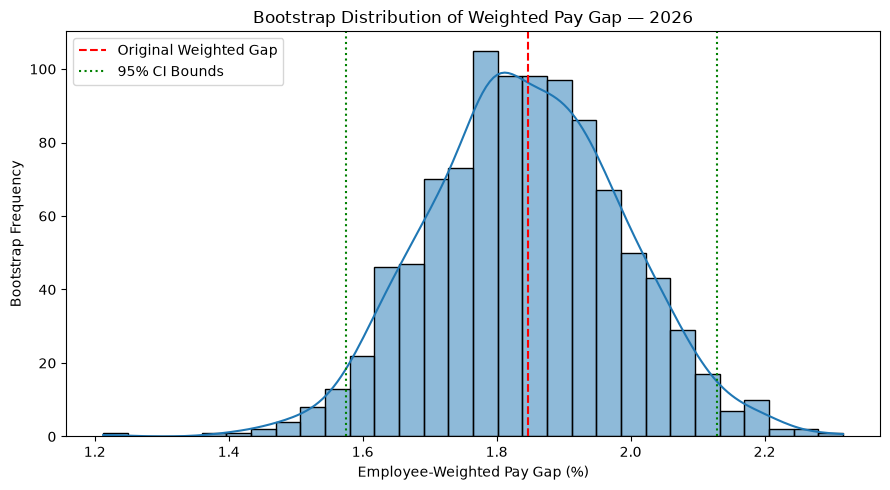

In [20]:

# Step 21 — Bootstrap Confidence Interval for Weighted Pay Gap

# Use comparable groups from Step 19
bootstrap_data = combined_groups[
    ["Pay_Gap_Pct", "Total_Employees"]
].dropna().copy()

# Set reproducible random generator
rng = np.random.default_rng(42)

bootstrap_results = []

# Generate 1,000 bootstrap samples
for i in range(1000):

    # Resample comparable groups with replacement
    sample_indices = rng.choice(
        len(bootstrap_data),
        size=len(bootstrap_data),
        replace=True
    )

    sample = bootstrap_data.iloc[sample_indices]

    # Calculate employee-weighted gap
    sample_gap = np.average(
        sample["Pay_Gap_Pct"],
        weights=sample["Total_Employees"]
    )

    bootstrap_results.append(sample_gap)

# Calculate bootstrap confidence interval
ci_lower, ci_upper = np.percentile(
    bootstrap_results, [2.5, 97.5]
)

print("Comparable Groups:", len(bootstrap_data))

print(
    "Original Weighted Pay Gap (%):",
    round(combined_weighted_gap, 2)
)

print("Bootstrap Iterations:", len(bootstrap_results))

print(
    "95% Bootstrap Confidence Interval:",
    (round(ci_lower, 2), round(ci_upper, 2))
)

# Visualize bootstrap distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    bootstrap_results,
    bins=30,
    kde=True
)

plt.axvline(
    combined_weighted_gap,
    color="red",
    linestyle="--",
    label="Original Weighted Gap"
)

plt.axvline(
    ci_lower,
    color="green",
    linestyle=":",
    label="95% CI Bounds"
)

plt.axvline(
    ci_upper,
    color="green",
    linestyle=":"
)

plt.title("Bootstrap Distribution of Weighted Pay Gap — 2026")
plt.xlabel("Employee-Weighted Pay Gap (%)")
plt.ylabel("Bootstrap Frequency")
plt.legend()
plt.tight_layout()
plt.show()


### Key Findings — Bootstrap Confidence Interval

- Bootstrap analysis was performed using **570 comparable groups and 1,000 resampling iterations**.
- The original employee-weighted male–female pay gap was **1.85%**.
- The estimated **95% bootstrap confidence interval was 1.57% to 2.13%**.
- The interval excludes zero, supporting a positive weighted pay gap under the group-level bootstrap assumptions.
- The results are consistent with the earlier statistical test, although the two methods estimate different measures.
- The findings indicate a persistent observed pay difference, but do not establish causation or prove discriminatory compensation practices.


# Employee-Level Adjusted Gender Pay Gap

## Objective

Estimate the association between gender and base salary after accounting for job, location, experience, tenure, and performance.

## Method

**Ordinary Least Squares (OLS) Regression**

## Model Specification

- **Dependent variable:** Natural logarithm of base salary
- **Independent variables:**
  - Gender
  - Job ID
  - Location
  - Years of experience
  - Employee tenure
  - 2026 performance rating

Male employees will be used as the **reference gender category**.

The regression model can be expressed as:

$$
\ln(\text{Base Salary}_i) =
\beta_0 + \beta_1 \text{Female}_i
+ \boldsymbol{\gamma}^{T}\mathbf{X}_i + \varepsilon_i
$$

Where:

- $\beta_0$ is the intercept.
- $\beta_1$ is the coefficient for female gender.
- $\mathbf{X}_i$ represents the included control variables, such as job ID, location, experience, tenure, and performance rating.
- $\boldsymbol{\gamma}$ represents the coefficients for the control variables.
- $\varepsilon_i$ is the error term.

## Percentage Interpretation

The adjusted gender pay gap is calculated as:

$$
\text{Adjusted Gap (\%)} =
\left(e^{\beta_{\text{Female}}}-1\right)\times100
$$

### Interpretation of Results

- **Negative adjusted gap:** Female employees have lower predicted base salaries than comparable male employees, conditional on the included characteristics.
- **Positive adjusted gap:** Female employees have higher predicted base salaries than comparable male employees, conditional on the included characteristics.
- **Zero adjusted gap:** The model estimates no difference in predicted base salaries by gender, conditional on the included characteristics.

## Important Considerations

- The model accounts for differences in job, location, experience, tenure, and performance through regression adjustment.
- Job ID and location should generally be represented using categorical indicators rather than treated as continuous numerical variables.
- The female coefficient estimates the salary difference associated with female gender after holding the included characteristics constant.
- Because the dependent variable is the natural logarithm of base salary, the percentage interpretation uses the exponential transformation of the female coefficient.
- The model should be assessed for relevant assumptions, including functional form, multicollinearity, and heteroskedasticity. Robust standard errors may be appropriate for statistical inference.

This is an **observational model that identifies conditional associations, not causal effects**. Results depend on the included variables, data quality, model specification, and underlying assumptions. The adjusted gap should not be interpreted as definitive evidence of gender-based pay discrimination.


In [21]:

# Step 22 — Employee-Level Adjusted Gender Pay Gap

import statsmodels.formula.api as smf

# Prepare employee-level analysis data
regression_data = pay_equity_2026[
    pay_equity_2026["Gender"].isin(["Male", "Female"])
].copy()

# Add 2026 performance ratings
regression_data = regression_data.merge(
    performance_2026,
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

# Select required variables
regression_columns = [
    "Base_Salary",
    "Gender",
    "Job_ID",
    "Location",
    "Years_Experience",
    "Tenure_Years_2026",
    "Performance_Rating"
]

regression_data = regression_data[
    regression_columns
].dropna().copy()

# Create log salary variable
regression_data["Log_Base_Salary"] = np.log(
    regression_data["Base_Salary"]
)

# Fit regression with robust standard errors
regression_model = smf.ols(
    formula=(
        "Log_Base_Salary ~ "
        "C(Gender, Treatment(reference='Male')) + "
        "C(Job_ID) + "
        "C(Location) + "
        "Years_Experience + "
        "Tenure_Years_2026 + "
        "C(Performance_Rating)"
    ),
    data=regression_data
).fit(cov_type="HC3")

# Extract female coefficient
female_term = (
    "C(Gender, Treatment(reference='Male'))[T.Female]"
)

female_coefficient = regression_model.params[female_term]
female_p_value = regression_model.pvalues[female_term]

# Convert log coefficient to percentage
adjusted_gap_pct = (
    np.exp(female_coefficient) - 1
) * 100

# Confidence interval
lower, upper = regression_model.conf_int().loc[
    female_term
]

adjusted_ci = (
    (np.exp(lower) - 1) * 100,
    (np.exp(upper) - 1) * 100
)

print("Employees Included:", len(regression_data))

print("Model R-Squared:", round(regression_model.rsquared, 4))

print("Female Coefficient:", round(female_coefficient, 6))

print("Adjusted Female vs Male Difference (%):",
      round(adjusted_gap_pct, 2))

print("P-Value:", f"{female_p_value:.6f}")

print(
    "95% Confidence Interval (%):",
    tuple(round(float(x), 2) for x in adjusted_ci)
)


Employees Included: 9863
Model R-Squared: 0.9944
Female Coefficient: -0.01963
Adjusted Female vs Male Difference (%): -1.94
P-Value: 0.000000
95% Confidence Interval (%): (-2.16, -1.73)


### Key Findings — Adjusted Gender Pay Gap Regression

- The regression analysis included **9,863 employees** with complete data.
- After accounting for job ID, location, experience, tenure, and performance rating, the estimated female–male base salary difference was **-1.94%**.
- The gender coefficient was statistically significant (**p < 0.000001**).
- The 95% confidence interval ranged from **-2.16% to -1.73%**, excluding zero.
- The model achieved an **R-squared of 0.9944**, indicating a very high proportion of explained variation in log base salary.
- The adjusted results suggest a persistent association between gender and base salary after accounting for the included employee characteristics.
- These results do not establish that gender caused the salary difference or prove discriminatory compensation practices.

Observations: 9863
R-Squared: 0.9944
Adjusted R-Squared: 0.9944
Mean Residual: 0.0
Residual Standard Deviation: 0.0558
RMSE (Log Salary): 0.0558


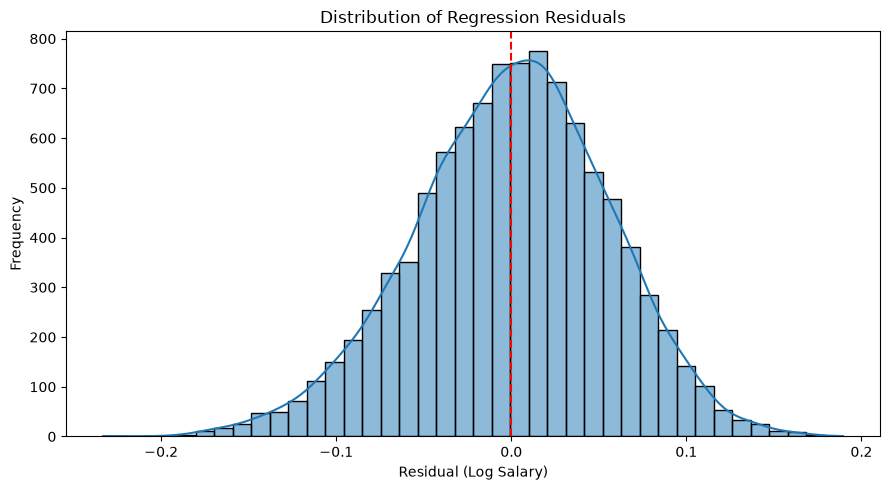

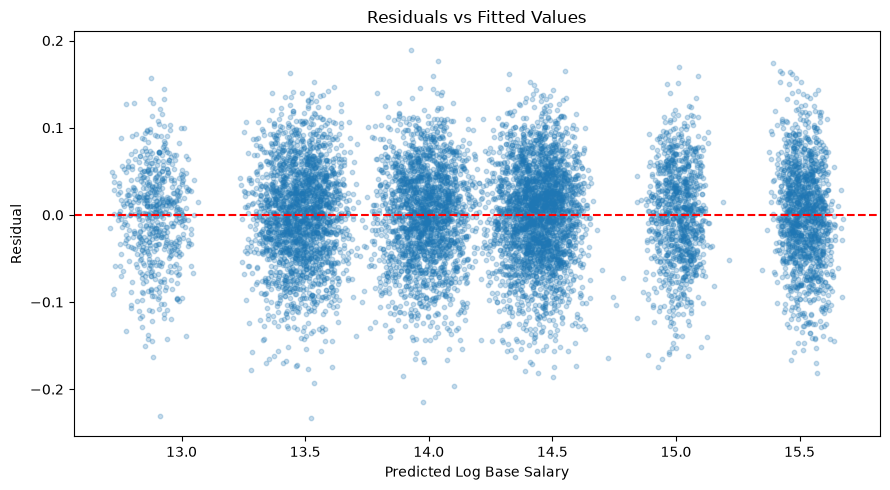

In [22]:

# Step 23 — Regression Model Diagnostics

# Extract fitted values and residuals
fitted_values = regression_model.fittedvalues
residuals = regression_model.resid

# Calculate diagnostic metrics
print("Observations:", int(regression_model.nobs))

print(
    "R-Squared:",
    round(regression_model.rsquared, 4)
)

print(
    "Adjusted R-Squared:",
    round(regression_model.rsquared_adj, 4)
)

print(
    "Mean Residual:",
    round(residuals.mean(), 6)
)

print(
    "Residual Standard Deviation:",
    round(residuals.std(), 4)
)

print(
    "RMSE (Log Salary):",
    round(np.sqrt(np.mean(residuals ** 2)), 4)
)

# Plot residual distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution of Regression Residuals")
plt.xlabel("Residual (Log Salary)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Plot residuals against fitted values
plt.figure(figsize=(9, 5))

plt.scatter(
    fitted_values,
    residuals,
    alpha=0.25,
    s=10
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Residuals vs Fitted Values")
plt.xlabel("Predicted Log Base Salary")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()


### Key Findings — Regression Model Diagnostics

- The regression model includes **9,863 employees** and achieves an **R-squared of 0.9944**.
- Residuals are approximately centered around zero, with a mean of **0.0000**.
- The residual standard deviation and RMSE are both **0.0558 log-salary units**.
- The residual distribution is approximately bell-shaped, without substantial visual asymmetry.
- The residual-versus-fitted plot shows distinct salary-level clusters, with no obvious nonlinear pattern.
- The diagnostics do not reveal a major model-fit problem, although the unusually high R-squared and possible differences in residual variance warrant caution.
- The model uses heteroskedasticity-robust standard errors, but unmeasured factors and observational-data limitations remain.


# Sensitivity Analysis — Gender Pay Gap Across Regression Models

## Objective

Examine whether the estimated female–male base salary difference remains consistent as additional employee characteristics are included in regression models.

All models use the **same employee sample** to make comparisons more meaningful and reduce differences attributable to changes in sample composition.

## Model Specifications

1. **Model 1 — Gender Only**
   - Gender

2. **Model 2 — Job and Location Adjusted**
   - Gender
   - Job ID
   - Location

3. **Model 3 — Fully Adjusted**
   - Gender
   - Job ID
   - Location
   - Years of experience
   - Employee tenure
   - 2026 performance rating

## Dependent Variable

The natural logarithm of base salary:

$$
Y_i = \ln(\text{Base Salary}_i)
$$

## Gender Pay Gap Formula

The female regression coefficient is converted into a percentage salary difference using:

$$
\text{Estimated Gender Pay Gap (\%)} =
\left(e^{\beta_{\text{Female}}}-1\right)\times100
$$

Where $\beta_{\text{Female}}$ represents the estimated female coefficient, with male employees as the reference category.

## Analysis Methodology

1. Use the same eligible employee sample for all three regression models.
2. Estimate Model 1 using gender as the only independent variable.
3. Estimate Model 2 by adding job ID and location controls.
4. Estimate Model 3 by additionally controlling for experience, tenure, and 2026 performance rating.
5. Convert the female coefficient from each model into a percentage salary difference.
6. Compare the estimated gender pay gaps across the three models to assess how the results change as additional characteristics are included.

## Interpretation of Results

- **Negative adjusted gap:** Female employees have lower predicted base salaries than male employees, conditional on the variables included in the model.
- **Positive adjusted gap:** Female employees have higher predicted base salaries than male employees, conditional on the variables included in the model.
- **Gap moves closer to zero:** The estimated difference becomes smaller after adding controls.
- **Gap moves farther from zero:** The estimated difference becomes larger after adding controls.
- **Gap changes direction:** The estimated association reverses between models, indicating sensitivity to the included characteristics.

## Important Considerations

- Using the same employee sample across all models improves comparability by preventing changes in sample composition from driving differences between estimates.
- Job ID and location should generally be represented using categorical indicators.
- Changes in the estimated gender pay gap reflect sensitivity to the included characteristics and model specification; they do not necessarily establish causal explanations.
- The analysis should consider coefficient uncertainty, confidence intervals, and appropriate standard errors when interpreting differences across models.
- The fully adjusted model accounts only for the characteristics included in the regression and may not capture all relevant factors associated with salary differences.

This is a **sensitivity analysis of observational regression models**, not a causal analysis. The results should be interpreted as conditional associations rather than definitive evidence of gender-based pay discrimination.


,Model,Employees,Adjusted_Gap_Pct,CI_Lower_Pct,CI_Upper_Pct,R_Squared
0,Model 1 - Gender Only,9863,-1.00,-3.88,1.98,0.00
1,Model 2 - Job and Location,9863,-1.93,-2.18,-1.68,0.99
2,Model 3 - Fully Adjusted,9863,-1.94,-2.16,-1.73,0.99


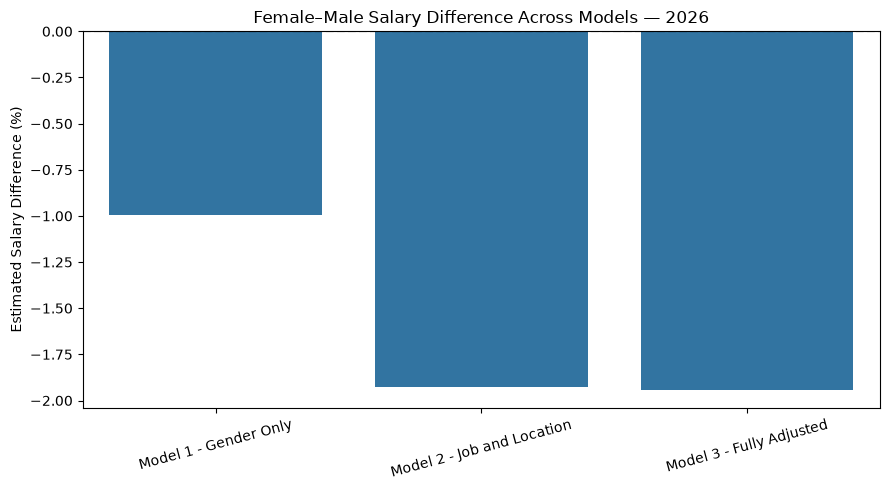

In [23]:

# Step 24 — Regression Sensitivity Analysis

# Use the same complete-case employee sample
model_data = regression_data.copy()

# Define regression specifications
model_formulas = {
    "Model 1 - Gender Only":
        "Log_Base_Salary ~ "
        "C(Gender, Treatment(reference='Male'))",

    "Model 2 - Job and Location":
        "Log_Base_Salary ~ "
        "C(Gender, Treatment(reference='Male')) + "
        "C(Job_ID) + C(Location)",

    "Model 3 - Fully Adjusted":
        "Log_Base_Salary ~ "
        "C(Gender, Treatment(reference='Male')) + "
        "C(Job_ID) + C(Location) + "
        "Years_Experience + Tenure_Years_2026 + "
        "C(Performance_Rating)"
}

results = []

female_term = (
    "C(Gender, Treatment(reference='Male'))[T.Female]"
)

# Fit each model
for model_name, formula in model_formulas.items():

    model = smf.ols(
        formula=formula,
        data=model_data
    ).fit(cov_type="HC3")

    coefficient = model.params[female_term]

    ci_lower, ci_upper = model.conf_int().loc[female_term]

    results.append({
        "Model": model_name,
        "Employees": int(model.nobs),
        "Adjusted_Gap_Pct": (
            np.exp(coefficient) - 1
        ) * 100,
        "CI_Lower_Pct": (
            np.exp(ci_lower) - 1
        ) * 100,
        "CI_Upper_Pct": (
            np.exp(ci_upper) - 1
        ) * 100,
        "R_Squared": model.rsquared
    })

# Create comparison table
model_comparison = pd.DataFrame(results)

display(model_comparison.round(4))

# Visualize adjusted gender difference across models
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Adjusted_Gap_Pct"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Female–Male Salary Difference Across Models — 2026")
plt.ylabel("Estimated Salary Difference (%)")
plt.xlabel("")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Key Findings — Regression Sensitivity Analysis

- Three regression models were compared using the same **9,863 employees**.
- The gender-only model estimated a **-1.00%** female–male salary difference, with a confidence interval that included zero.
- After accounting for job and location, the estimated difference increased to **-1.93%**.
- The fully adjusted model estimated a **-1.94%** difference after additionally including experience, tenure, and performance.
- The small change between Models 2 and 3 indicates that the estimated gender difference is relatively stable across these two specifications.
- The results support a persistent conditional association between gender and base salary, but do not establish causation or prove discrimination.

In [24]:

# Step 25 — Regression Sample Coverage and Exclusion Audit

# All male and female employees
eligible_employees = pay_equity_2026[
    pay_equity_2026["Gender"].isin(["Male", "Female"])
].copy()

# Identify employees included in regression
included_ids = set(
    regression_data.index
) if "Employee_ID" not in regression_data.columns else set(
    regression_data["Employee_ID"]
)

# Recreate complete-case eligibility using original fields
audit_data = eligible_employees.merge(
    performance_2026,
    on="Employee_ID",
    how="left",
    validate="one_to_one"
)

required_columns = [
    "Base_Salary",
    "Gender",
    "Job_ID",
    "Location",
    "Years_Experience",
    "Tenure_Years_2026",
    "Performance_Rating"
]

audit_data["Included_in_Regression"] = (
    audit_data[required_columns].notna().all(axis=1)
)

# Summarize inclusion by gender
coverage_summary = (
    audit_data.groupby("Gender")
    .agg(
        Total_Employees=("Employee_ID", "count"),
        Included=("Included_in_Regression", "sum")
    )
    .reset_index()
)

coverage_summary["Excluded"] = (
    coverage_summary["Total_Employees"]
    - coverage_summary["Included"]
)

coverage_summary["Coverage_Pct"] = (
    coverage_summary["Included"]
    / coverage_summary["Total_Employees"] * 100
)

print("Eligible Employees:", len(audit_data))

print(
    "Included in Regression:",
    audit_data["Included_in_Regression"].sum()
)

print(
    "Excluded Employees:",
    (~audit_data["Included_in_Regression"]).sum()
)

print("\nRegression Coverage by Gender:")
display(coverage_summary.round(2))

print("\nMissing Values in Required Variables:")
display(audit_data[required_columns].isna().sum())


Eligible Employees: 9888
Included in Regression: 9863
Excluded Employees: 25

Regression Coverage by Gender:


,Gender,Total_Employees,Included,Excluded,Coverage_Pct
0,Female,4738,4724,14,99.70
1,Male,5150,5139,11,99.79



Missing Values in Required Variables:


Base_Salary            0
Gender                 0
Job_ID                 0
Location               0
Years_Experience      25
Tenure_Years_2026      0
Performance_Rating     0
dtype: int64

### Key Findings — Regression Sample Coverage

- The regression analysis includes **9,863 of 9,888 eligible male and female employees**, achieving **99.75% coverage**.
- Only **25 employees** were excluded because their years of experience were missing.
- Female employee coverage was **99.70%**, compared with **99.79%** for male employees.
- All other required regression variables had complete data.
- The high sample coverage and small gender difference in exclusion rates reduce concerns about substantial sample loss, although missing-data bias cannot be ruled out entirely.

In [25]:

# Step 26 — Missing Experience Sensitivity Analysis

# Use all eligible male and female employees
sensitivity_data = audit_data.copy()

# Flag employees with missing experience
sensitivity_data["Experience_Missing"] = (
    sensitivity_data["Years_Experience"].isna().astype(int)
)

# Fill missing experience with the sample median
median_experience = sensitivity_data[
    "Years_Experience"
].median()

sensitivity_data["Experience_Filled"] = (
    sensitivity_data["Years_Experience"].fillna(
        median_experience
    )
)

# Create log base salary
sensitivity_data["Log_Base_Salary"] = np.log(
    sensitivity_data["Base_Salary"]
)

# Fit sensitivity model
sensitivity_model = smf.ols(
    formula=(
        "Log_Base_Salary ~ "
        "C(Gender, Treatment(reference='Male')) + "
        "C(Job_ID) + C(Location) + "
        "Experience_Filled + Experience_Missing + "
        "Tenure_Years_2026 + "
        "C(Performance_Rating)"
    ),
    data=sensitivity_data
).fit(cov_type="HC3")

# Extract female coefficient
female_term = (
    "C(Gender, Treatment(reference='Male'))[T.Female]"
)

sensitivity_coefficient = sensitivity_model.params[
    female_term
]

sensitivity_gap = (
    np.exp(sensitivity_coefficient) - 1
) * 100

# Compare against original model
print("Original Model Employees:",
      int(regression_model.nobs))

print("Sensitivity Model Employees:",
      int(sensitivity_model.nobs))

print(
    "Original Adjusted Female-Male Difference (%):",
    round(adjusted_gap_pct, 2)
)

print(
    "Sensitivity Adjusted Female-Male Difference (%):",
    round(sensitivity_gap, 2)
)

print(
    "Difference (Percentage Points):",
    round(sensitivity_gap - adjusted_gap_pct, 4)
)

print(
    "Sensitivity Model R-Squared:",
    round(sensitivity_model.rsquared, 4)
)


Original Model Employees: 9863
Sensitivity Model Employees: 9888
Original Adjusted Female-Male Difference (%): -1.94
Sensitivity Adjusted Female-Male Difference (%): -1.94
Difference (Percentage Points): 0.0083
Sensitivity Model R-Squared: 0.9944


### Key Findings — Missing Experience Sensitivity Analysis

- The original regression included **9,863 employees**, while the sensitivity model included all **9,888 eligible male and female employees**.
- Missing experience values were replaced using median imputation, with an additional indicator identifying imputed records.
- Both models produced an adjusted female–male salary difference of approximately **-1.94%**.
- The estimated difference changed by only **0.0083 percentage points**.
- The sensitivity model maintained an **R-squared of 0.9944**.
- These findings indicate that excluding the 25 employees with missing experience does not materially influence the estimated gender pay difference under the tested imputation approach.

In [27]:

# Recalculate bootstrap confidence interval
# using the original Step 21 bootstrap results

bootstrap_ci_lower, bootstrap_ci_upper = np.percentile(
    bootstrap_results,
    [2.5, 97.5]
)

print(
    "Bootstrap 95% Confidence Interval:",
    (
        round(float(bootstrap_ci_lower), 2),
        round(float(bootstrap_ci_upper), 2)
    )
)

print(
    "Bootstrap CI Excludes Zero:",
    not (bootstrap_ci_lower <= 0 <= bootstrap_ci_upper)
)


Bootstrap 95% Confidence Interval: (1.57, 2.13)
Bootstrap CI Excludes Zero: True


## Final Business Insights and Recommendations — 2026

### 1. Executive Summary

The Compensation & Pay Equity Analysis examined salary differences across a workforce of **10,000 employees**, focusing on gender-based compensation patterns.

The analysis combined comparable job-group comparisons, experience and performance adjustments, statistical testing, and regression modeling.

**The principal finding is an adjusted female–male base salary difference of -1.94%, favoring male employees**, after accounting for job, location, experience, tenure, and performance.

### 2. Key Business Findings

**Overall Gender Pay Gap**

- The unadjusted male–female average base salary gap was **1.20%**.
- Within comparable job and location groups, the employee-weighted gap was **1.89%**.

**Experience and Performance**

- The experience-stratified weighted gap was **1.95%**.
- The performance-stratified weighted gap was **1.86%**.
- Combining job, location, experience, and performance produced a weighted gap of **1.85%** across 6,284 employees.

**Salary Band Positioning**

- Male employees were positioned an average of **4.09 percentage points higher** within salary bands across comparable groups.
- This suggests that salary positioning warrants review even when employees share the same job and location.

**Statistical Evidence**

- The unweighted mean comparable-group gap was **1.88%**, with a statistically significant one

In [28]:

# Step 29 — Final Pay Equity Analysis Validation

validation_checks = {
    "Total Employees": len(pay_equity_2026) == 10000,

    "Unique Employee IDs":
        pay_equity_2026["Employee_ID"].nunique() == 10000,

    "No Missing Base Salaries":
        pay_equity_2026["Base_Salary"].isna().sum() == 0,

    "Comparable Groups Validated":
        len(comparable_groups) == 281,

    "Combined Groups Validated":
        len(combined_groups) == 570,

    "Regression Sample Validated":
        int(regression_model.nobs) == 9863,

    "Sensitivity Sample Validated":
        int(sensitivity_model.nobs) == 9888,

    "Bootstrap Confidence Interval Excludes Zero":
        bootstrap_ci_lower > 0 and bootstrap_ci_upper > 0,

    "Adjusted Gender Gap Calculated":
        np.isfinite(adjusted_gap_pct),

    "Final Results Table Complete":
        len(pay_equity_results) == 8
}

validation_results = pd.DataFrame({
    "Validation_Check": list(validation_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in validation_checks.values()
    ]
})

display(validation_results)

print(
    "Total Checks:",
    len(validation_checks)
)

print(
    "Passed Checks:",
    sum(validation_checks.values())
)

print(
    "Failed Checks:",
    len(validation_checks) - sum(validation_checks.values())
)

if all(validation_checks.values()):
    print("FINAL STATUS: ALL VALIDATIONS PASSED")
else:
    print("FINAL STATUS: REVIEW FAILED CHECKS")


,Validation_Check,Status
0,Total Employees,PASS
1,Unique Employee IDs,PASS
2,No Missing Base Salaries,PASS
3,Comparable Groups Validated,PASS
4,Combined Groups Validated,PASS
5,Regression Sample Validated,PASS
6,Sensitivity Sample Validated,PASS
7,Bootstrap Confidence Interval Excludes Zero,PASS
8,Adjusted Gender Gap Calculated,PASS
9,Final Results Table Complete,PASS


Total Checks: 10
Passed Checks: 10
Failed Checks: 0
FINAL STATUS: ALL VALIDATIONS PASSED
